## 1단계 : 구종데이터를 가져오자

In [1]:
import pandas as pd

df_2025 = pd.read_parquet("./Data/raw/kbo_pbp_2025.parquet")
df_2026 = pd.read_parquet("./Data/raw/kbo_pbp_2026.parquet")

In [2]:
df_2025

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
0,20250322HHKT02025,2025-03-22,KT,HH,1,top,1,1,66704,54354,...,R,2.193055,field_out,0,0,1,0,NaN,NaN,NaN
1,20250322HHKT02025,2025-03-22,KT,HH,1,top,1,2,66704,54354,...,R,2.303758,field_out,0,0,1,0,NaN,NaN,NaN
2,20250322HHKT02025,2025-03-22,KT,HH,1,top,1,3,66704,54354,...,R,1.137694,field_out,0,0,1,0,NaN,NaN,NaN
3,20250322HHKT02025,2025-03-22,KT,HH,1,top,1,4,66704,54354,...,R,2.309194,field_out,0,0,1,0,NaN,NaN,NaN
4,20250322HHKT02025,2025-03-22,KT,HH,1,top,1,5,66704,54354,...,R,1.803736,field_out,0,0,1,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217965,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,1,66354,50430,...,L,3.028251,single,8,8,0,0,66354,69636,55636
217966,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,2,66354,50430,...,L,3.994304,single,8,8,0,0,66354,69636,55636
217967,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,3,66354,50430,...,L,2.467217,single,8,8,0,0,66354,69636,55636
217968,20251004SSHT02025,2025-10-04,HT,SS,9,bot,85,1,66614,50430,...,L,0.144706,sac_fly,9,8,1,1,66354,NaN,69636


In [3]:
df_2025.columns

Index(['game_pk', 'game_date', 'home_team', 'away_team', 'inning',
       'inning_topbot', 'at_bat_number', 'pitch_number', 'batter', 'pitcher',
       'batter_name', 'pitcher_name', 'balls', 'strikes', 'outs_when_up',
       'on_1b', 'on_2b', 'on_3b', 'home_score', 'away_score', 'pitch_result',
       'type', 'pitch_type', 'pitch_name', '_naver_pitch_name',
       'release_speed_kmh', 'plate_x', 'sz_top', 'sz_bot', 'release_pos_x',
       'release_pos_y', 'release_pos_z', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az',
       'stand', 'plate_z', 'events', 'post_home_score', 'post_away_score',
       'post_outs', 'runs_scored', 'post_on_1b', 'post_on_2b', 'post_on_3b'],
      dtype='str')

In [4]:
df_2025.shape

(217970, 48)

In [5]:
df_2026.shape

(144779, 48)

In [6]:
df_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 217970 entries, 0 to 217969
Data columns (total 48 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   game_pk            217970 non-null  str    
 1   game_date          217970 non-null  str    
 2   home_team          217970 non-null  str    
 3   away_team          217970 non-null  str    
 4   inning             217970 non-null  int64  
 5   inning_topbot      217970 non-null  str    
 6   at_bat_number      217970 non-null  int64  
 7   pitch_number       217970 non-null  int64  
 8   batter             217970 non-null  str    
 9   pitcher            217970 non-null  str    
 10  batter_name        217970 non-null  str    
 11  pitcher_name       217970 non-null  str    
 12  balls              217970 non-null  int64  
 13  strikes            217970 non-null  int64  
 14  outs_when_up       217970 non-null  int64  
 15  on_1b              77990 non-null   str    
 16  on_2b        

## 2단계 : 가져온 데이터를 확인하자
 - 대부분의 데이터가 217970으로 끝나는데 217848, 217765개수를 가지고있는 컬럼이 있음
 - 구종, 구속, 그리고 스트라이크존에 어느구역에 꽂혔는지의 위치값을 알 수 있음
 - 불필요한 컬럼이 없음.
   

In [17]:
df_2025_kia_batter = df_2025[
    (
        (df_2025["home_team"]=="HT") & (df_2025["inning_topbot"]=="bot")
    )
    |
    (
        (df_2025["away_team"]=="HT") & (df_2025["inning_topbot"]=="top")
    )
]
## 조건1 & 조건2
## 홈팀이 기아 이면서 후공<--공격을 선공(top)이냐 후공(bot)이냐
## 조건3 & 조건4
## 어웨이팀이 기아이면서 선공이냐


In [7]:
import numpy as np

In [14]:
df_2025["home_team"].unique()

<ArrowStringArray>
['KT', 'LG', 'HT', 'SK', 'SS', 'HH', 'LT', 'NC', 'WO', 'OB']
Length: 10, dtype: str

In [15]:
df_2025["inning_topbot"].unique()

<ArrowStringArray>
['top', 'bot']
Length: 2, dtype: str

In [19]:
df_2025_kia_batter
## 약 22000개 가량의 데이터 압축

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
636,20250322NCHT02025,2025-03-22,HT,NC,1,bot,4,1,64646,55912,...,R,2.739038,field_out,0,0,1,0,NaN,NaN,NaN
637,20250322NCHT02025,2025-03-22,HT,NC,1,bot,4,2,64646,55912,...,R,2.112632,field_out,0,0,1,0,NaN,NaN,NaN
638,20250322NCHT02025,2025-03-22,HT,NC,1,bot,4,3,64646,55912,...,R,2.874573,field_out,0,0,1,0,NaN,NaN,NaN
639,20250322NCHT02025,2025-03-22,HT,NC,1,bot,5,1,52605,55912,...,R,-0.078887,field_out,0,0,2,0,NaN,NaN,NaN
640,20250322NCHT02025,2025-03-22,HT,NC,1,bot,5,2,52605,55912,...,R,3.101267,field_out,0,0,2,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217965,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,1,66354,50430,...,L,3.028251,single,8,8,0,0,66354,69636,55636
217966,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,2,66354,50430,...,L,3.994304,single,8,8,0,0,66354,69636,55636
217967,20251004SSHT02025,2025-10-04,HT,SS,9,bot,84,3,66354,50430,...,L,2.467217,single,8,8,0,0,66354,69636,55636
217968,20251004SSHT02025,2025-10-04,HT,SS,9,bot,85,1,66614,50430,...,L,0.144706,sac_fly,9,8,1,1,66354,NaN,69636


In [20]:
df_2025_kia_batter.shape

(22215, 48)

In [21]:
df_2025_kia_batter["batter_name"].unique()

<ArrowStringArray>
['박찬호', '김도영', '나성범', '위즈덤', '최형우', '김선빈', '이우성', '김태군', '최원준', '윤도현', '한준수',
 '홍종표', '박정우', '박재현', '김규성', '서건창', '변우혁', '최정용', '오선우', '한승택', '김호령', '정해원',
 '김석환', '황대인',  '박민', '고종욱', '이창진', '김기훈', '정현창', '주효상',  '박헌']
Length: 31, dtype: str

In [23]:
df_2025_kia_pitcher = df_2025[
    (
        (df_2025["home_team"]=="HT") & (df_2025["inning_topbot"]=="top")
    )
    |
    (
        (df_2025["away_team"]=="HT") & (df_2025["inning_topbot"]=="bot")
    )
]
df_2025_kia_pitcher
## 투수 데이터

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
624,20250322NCHT02025,2025-03-22,HT,NC,1,top,1,1,62907,54640,...,L,3.669349,field_out,0,0,1,0,NaN,NaN,NaN
625,20250322NCHT02025,2025-03-22,HT,NC,1,top,1,2,62907,54640,...,L,2.454229,field_out,0,0,1,0,NaN,NaN,NaN
626,20250322NCHT02025,2025-03-22,HT,NC,1,top,1,3,62907,54640,...,L,2.441240,field_out,0,0,1,0,NaN,NaN,NaN
627,20250322NCHT02025,2025-03-22,HT,NC,1,top,2,1,51907,54640,...,L,2.851058,strikeout,0,0,2,0,NaN,NaN,NaN
628,20250322NCHT02025,2025-03-22,HT,NC,1,top,2,2,51907,54640,...,L,2.262244,strikeout,0,0,2,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217951,20251004SSHT02025,2025-10-04,HT,SS,9,top,80,3,65586,50662,...,R,1.849297,strikeout,8,8,2,0,NaN,NaN,NaN
217952,20251004SSHT02025,2025-10-04,HT,SS,9,top,81,1,69416,50662,...,R,3.552964,strikeout,8,8,3,0,NaN,NaN,NaN
217953,20251004SSHT02025,2025-10-04,HT,SS,9,top,81,2,69416,50662,...,R,2.120395,strikeout,8,8,3,0,NaN,NaN,NaN
217954,20251004SSHT02025,2025-10-04,HT,SS,9,top,81,3,69416,50662,...,R,2.357225,strikeout,8,8,3,0,NaN,NaN,NaN


In [24]:
df_2025_kia_pitcher.shape

(21608, 48)

In [27]:
df_2025_kia_pitcher["pitcher_name"].unique()

<ArrowStringArray>
[ '네일', '곽도규', '조상우', '최지민', '전상현', '황동하', '양현종', '임기영', '이준영', '정해영',  '올러',
 '윤영철', '유승철', '김도현', '이형범', '김건국', '김대유', '윤중현', '김민재', '김기훈', '장재혁', '김현수',
 '성영탁', '홍원빈', '이호민', '김태형', '김민주', '이도현', '이의리', '김시훈', '한재승', '유지성', '김정엽',
 '이성원']
Length: 34, dtype: str

In [32]:
df_2026 = pd.read_parquet("./Data/raw/kbo_pbp_2026.parquet")
df_2026

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
0,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,1,65653,55855,...,R,3.758225,walk,0,0,0,0,65653,NaN,NaN
1,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,2,65653,55855,...,R,1.862381,walk,0,0,0,0,65653,NaN,NaN
2,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,3,65653,55855,...,R,0.955346,walk,0,0,0,0,65653,NaN,NaN
3,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,4,65653,55855,...,R,3.244286,walk,0,0,0,0,65653,NaN,NaN
4,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,5,65653,55855,...,R,3.825042,walk,0,0,0,0,65653,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144774,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,3,52605,76118,...,R,3.116588,strikeout,3,8,3,0,NaN,NaN,NaN
144775,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,4,52605,76118,...,R,1.960814,strikeout,3,8,3,0,NaN,NaN,NaN
144776,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,5,52605,76118,...,R,2.567185,strikeout,3,8,3,0,NaN,NaN,NaN
144777,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,6,52605,76118,...,R,1.523456,strikeout,3,8,3,0,NaN,NaN,NaN


In [37]:
#2026년도 데이터 만들기 (타자)
df_2026_kia_batter = df_2026[
    (
        (df_2026["home_team"]=="HT") & (df_2026["inning_topbot"]=="bot")
    )
    |
    (
        (df_2026["away_team"]=="HT") & (df_2026["inning_topbot"]=="top")
    )
]
df_2026_kia_batter

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
0,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,1,65653,55855,...,R,3.758225,walk,0,0,0,0,65653,NaN,NaN
1,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,2,65653,55855,...,R,1.862381,walk,0,0,0,0,65653,NaN,NaN
2,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,3,65653,55855,...,R,0.955346,walk,0,0,0,0,65653,NaN,NaN
3,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,4,65653,55855,...,R,3.244286,walk,0,0,0,0,65653,NaN,NaN
4,20260328HTSK02026,2026-03-28,SK,HT,1,top,1,5,65653,55855,...,R,3.825042,walk,0,0,0,0,65653,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144774,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,3,52605,76118,...,R,3.116588,strikeout,3,8,3,0,NaN,NaN,NaN
144775,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,4,52605,76118,...,R,1.960814,strikeout,3,8,3,0,NaN,NaN,NaN
144776,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,5,52605,76118,...,R,2.567185,strikeout,3,8,3,0,NaN,NaN,NaN
144777,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,6,52605,76118,...,R,1.523456,strikeout,3,8,3,0,NaN,NaN,NaN


In [38]:
#2026년도 투수 데이터 만들기
df_2026_kia_pitcher = df_2026[
    (
        (df_2026["home_team"]=="HT") & (df_2026["inning_topbot"]=="top")
    )
    |
    (
        (df_2026["away_team"]=="HT") & (df_2026["inning_topbot"]=="bot")
    )
]
df_2026_kia_pitcher

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
26,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,1,67893,54640,...,L,2.886582,single,0,2,0,0,67893,NaN,NaN
27,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,2,67893,54640,...,L,3.609609,single,0,2,0,0,67893,NaN,NaN
28,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,3,67893,54640,...,L,3.917747,single,0,2,0,0,67893,NaN,NaN
29,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,4,67893,54640,...,L,2.137785,single,0,2,0,0,67893,NaN,NaN
30,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,5,67893,54640,...,L,2.261917,single,0,2,0,0,67893,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144760,20260726WOHT02026,2026-07-26,HT,WO,9,top,76,4,79608,52639,...,R,2.681141,field_out,3,8,2,0,NaN,NaN,NaN
144761,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,1,65898,52639,...,L,3.323419,strikeout,3,8,3,0,NaN,NaN,NaN
144762,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,2,65898,52639,...,L,3.739070,strikeout,3,8,3,0,NaN,NaN,NaN
144763,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,3,65898,52639,...,L,4.065234,strikeout,3,8,3,0,NaN,NaN,NaN


In [39]:
##2025 , 2026년 데이터 통합하기 (편리하게 사용하기 위해 season이란 컬럼만들
df_2026_kia_pitcher["season"] = 2026
df_2025_kia_pitcher["season"] = 2025
df_2026_kia_batter["season"] = 2026
df_2025_kia_batter["season"] = 2025

In [40]:
df_2026_kia_pitcher.head()

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b,season
26,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,1,67893,54640,...,2.886582,single,0,2,0,0,67893,NaN,NaN,2026
27,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,2,67893,54640,...,3.609609,single,0,2,0,0,67893,NaN,NaN,2026
28,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,3,67893,54640,...,3.917747,single,0,2,0,0,67893,NaN,NaN,2026
29,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,4,67893,54640,...,2.137785,single,0,2,0,0,67893,NaN,NaN,2026
30,20260328HTSK02026,2026-03-28,SK,HT,1,bot,7,5,67893,54640,...,2.261917,single,0,2,0,0,67893,NaN,NaN,2026


In [41]:
##concat으로 2025,2026 타자 데이터 합치기
df_kia_batter = pd.concat(
    [df_2025_kia_batter, df_2026_kia_batter],
    ignore_index=True
)
df_kia_batter.shape

(36604, 49)

In [42]:
df_kia_pitcher = pd.concat(
    [df_2025_kia_pitcher, df_2026_kia_pitcher],
    ignore_index=True
)
df_kia_pitcher.shape

(36267, 49)

In [43]:
# 연도별 행 개수 확인
print(df_kia_batter["season"].value_counts())
print(df_kia_pitcher["season"].value_counts())

season
2025    22215
2026    14389
Name: count, dtype: int64
season
2025    21608
2026    14659
Name: count, dtype: int64


In [44]:
#타자데이터 저장하기
df_kia_batter.to_parquet(
    "./Data/processed/KIA_batter_2025_2026.parquet",
    index=False
)

In [45]:
#투수데이터 저장하기
df_kia_pitcher.to_parquet(
    "./Data/processed/KIA_pitcher_2025_2026.parquet",
    index=False
)

In [46]:
df_kia_batter.to_csv(
    "./Data/processed/KIA_batter_2025_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

In [47]:
df_kia_pitcher.to_csv(
    "./Data/processed/KIA_pitcher_2025_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

In [49]:
df_2024 = pd.read_parquet("./Data/raw/kbo_pbp_2024.parquet")
df_2024

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
0,20240323HHLG02024,2024-03-23,LG,HH,1,top,1,1,68743,54134,...,L,3.038824,field_out,0,0,1,0,NaN,NaN,NaN
1,20240323HHLG02024,2024-03-23,LG,HH,1,top,1,2,68743,54134,...,L,-0.930419,field_out,0,0,1,0,NaN,NaN,NaN
2,20240323HHLG02024,2024-03-23,LG,HH,1,top,1,3,68743,54134,...,L,3.268863,field_out,0,0,1,0,NaN,NaN,NaN
3,20240323HHLG02024,2024-03-23,LG,HH,1,top,2,1,54730,54134,...,R,2.723714,single,0,0,1,0,54730,NaN,NaN
4,20240323HHLG02024,2024-03-23,LG,HH,1,top,2,2,54730,54134,...,R,2.919064,single,0,0,1,0,54730,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223272,20241001LTNC02024,2024-10-01,NC,LT,9,bot,72,2,66965,62528,...,L,3.047337,field_out,1,5,3,0,50903,NaN,NaN
223273,20241001LTNC02024,2024-10-01,NC,LT,9,bot,72,3,66965,62528,...,L,3.367221,field_out,1,5,3,0,50903,NaN,NaN
223274,20241001LTNC02024,2024-10-01,NC,LT,9,bot,72,4,66965,62528,...,L,2.806879,field_out,1,5,3,0,50903,NaN,NaN
223275,20241001LTNC02024,2024-10-01,NC,LT,9,bot,72,5,66965,62528,...,L,2.699571,field_out,1,5,3,0,50903,NaN,NaN


In [50]:
#2024년도 데이터 만들기 (타자)
df_2024_kia_batter = df_2024[
    (
        (df_2024["home_team"]=="HT") & (df_2024["inning_topbot"]=="bot")
    )
    |
    (
        (df_2024["away_team"]=="HT") & (df_2024["inning_topbot"]=="top")
    )
]
df_2024_kia_batter

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
1197,20240323WOHT02024,2024-03-23,HT,WO,1,bot,6,1,64646,53375,...,R,3.243483,double,0,2,0,0,NaN,64646,NaN
1198,20240323WOHT02024,2024-03-23,HT,WO,1,bot,7,1,52605,53375,...,R,3.103147,field_out,0,2,1,0,NaN,64646,NaN
1199,20240323WOHT02024,2024-03-23,HT,WO,1,bot,7,2,52605,53375,...,R,1.674589,field_out,0,2,1,0,NaN,64646,NaN
1200,20240323WOHT02024,2024-03-23,HT,WO,1,bot,8,1,52630,53375,...,L,1.225017,single,0,2,1,0,NaN,52630,64646
1201,20240323WOHT02024,2024-03-23,HT,WO,1,bot,8,2,52630,53375,...,L,2.171797,single,0,2,1,0,NaN,52630,64646
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222693,20240930NCHT02024,2024-09-30,HT,NC,8,bot,82,3,65653,69969,...,R,2.707883,field_out,10,5,2,0,69636,69727,NaN
222694,20240930NCHT02024,2024-09-30,HT,NC,8,bot,83,1,63722,69969,...,R,2.291436,field_out,10,5,3,0,69636,69727,NaN
222695,20240930NCHT02024,2024-09-30,HT,NC,8,bot,83,2,63722,69969,...,R,3.190429,field_out,10,5,3,0,69636,69727,NaN
222696,20240930NCHT02024,2024-09-30,HT,NC,8,bot,83,3,63722,69969,...,R,3.361171,field_out,10,5,3,0,69636,69727,NaN


In [51]:
#2024년도 데이터 만들기 (투수)
df_2024_kia_pitcher = df_2024[
    (
        (df_2024["home_team"]=="HT") & (df_2024["inning_topbot"]=="top")
    )
    |
    (
        (df_2024["away_team"]=="HT") & (df_2024["inning_topbot"]=="bot")
    )
]
df_2024_kia_pitcher

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,stand,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b
1181,20240323WOHT02024,2024-03-23,HT,WO,1,top,1,1,67304,54612,...,L,2.719754,single,0,0,0,0,67304,NaN,NaN
1182,20240323WOHT02024,2024-03-23,HT,WO,1,top,2,1,53327,54612,...,L,2.503910,field_out,0,0,1,0,67304,NaN,NaN
1183,20240323WOHT02024,2024-03-23,HT,WO,1,top,2,2,53327,54612,...,L,2.980824,field_out,0,0,1,0,67304,NaN,NaN
1184,20240323WOHT02024,2024-03-23,HT,WO,1,top,3,1,64340,54612,...,R,2.528934,field_out,0,0,2,0,67304,NaN,NaN
1185,20240323WOHT02024,2024-03-23,HT,WO,1,top,3,2,64340,54612,...,R,2.550773,field_out,0,0,2,0,67304,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222715,20240930NCHT02024,2024-09-30,HT,NC,9,top,86,5,68912,50662,...,R,2.088912,field_out,10,5,2,0,NaN,51344,NaN
222716,20240930NCHT02024,2024-09-30,HT,NC,9,top,87,1,64022,50662,...,R,4.476946,strikeout,10,5,3,0,NaN,51344,NaN
222717,20240930NCHT02024,2024-09-30,HT,NC,9,top,87,2,64022,50662,...,R,1.221339,strikeout,10,5,3,0,NaN,51344,NaN
222718,20240930NCHT02024,2024-09-30,HT,NC,9,top,87,3,64022,50662,...,R,3.382296,strikeout,10,5,3,0,NaN,51344,NaN


In [53]:
df_2024_kia_pitcher["season"] = 2024

In [54]:
df_2024_kia_batter["season"] = 2024

In [64]:
df_2024_kia_batter.shape

(22323, 49)

In [65]:
df_2024_kia_pitcher.shape

(22477, 49)

In [56]:
# 2024 + 2025 + 2026 KIA 타자 데이터 통합
df_kia_batter = pd.concat(
    [
        df_2024_kia_batter,
        df_2025_kia_batter,
        df_2026_kia_batter
    ],
    ignore_index=True
)

df_kia_batter

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b,season
0,20240323WOHT02024,2024-03-23,HT,WO,1,bot,6,1,64646,53375,...,3.243483,double,0,2,0,0,NaN,64646,NaN,2024
1,20240323WOHT02024,2024-03-23,HT,WO,1,bot,7,1,52605,53375,...,3.103147,field_out,0,2,1,0,NaN,64646,NaN,2024
2,20240323WOHT02024,2024-03-23,HT,WO,1,bot,7,2,52605,53375,...,1.674589,field_out,0,2,1,0,NaN,64646,NaN,2024
3,20240323WOHT02024,2024-03-23,HT,WO,1,bot,8,1,52630,53375,...,1.225017,single,0,2,1,0,NaN,52630,64646,2024
4,20240323WOHT02024,2024-03-23,HT,WO,1,bot,8,2,52630,53375,...,2.171797,single,0,2,1,0,NaN,52630,64646,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58922,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,3,52605,76118,...,3.116588,strikeout,3,8,3,0,NaN,NaN,NaN,2026
58923,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,4,52605,76118,...,1.960814,strikeout,3,8,3,0,NaN,NaN,NaN,2026
58924,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,5,52605,76118,...,2.567185,strikeout,3,8,3,0,NaN,NaN,NaN,2026
58925,20260726WOHT02026,2026-07-26,HT,WO,9,bot,80,6,52605,76118,...,1.523456,strikeout,3,8,3,0,NaN,NaN,NaN,2026


In [57]:
# 2024 + 2025 + 2026 KIA 투수 데이터 통합
df_kia_pitcher = pd.concat(
    [
        df_2024_kia_pitcher,
        df_2025_kia_pitcher,
        df_2026_kia_pitcher
    ],
    ignore_index=True
)

df_kia_pitcher

,game_pk,game_date,home_team,away_team,inning,inning_topbot,at_bat_number,pitch_number,batter,pitcher,...,plate_z,events,post_home_score,post_away_score,post_outs,runs_scored,post_on_1b,post_on_2b,post_on_3b,season
0,20240323WOHT02024,2024-03-23,HT,WO,1,top,1,1,67304,54612,...,2.719754,single,0,0,0,0,67304,NaN,NaN,2024
1,20240323WOHT02024,2024-03-23,HT,WO,1,top,2,1,53327,54612,...,2.503910,field_out,0,0,1,0,67304,NaN,NaN,2024
2,20240323WOHT02024,2024-03-23,HT,WO,1,top,2,2,53327,54612,...,2.980824,field_out,0,0,1,0,67304,NaN,NaN,2024
3,20240323WOHT02024,2024-03-23,HT,WO,1,top,3,1,64340,54612,...,2.528934,field_out,0,0,2,0,67304,NaN,NaN,2024
4,20240323WOHT02024,2024-03-23,HT,WO,1,top,3,2,64340,54612,...,2.550773,field_out,0,0,2,0,67304,NaN,NaN,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58739,20260726WOHT02026,2026-07-26,HT,WO,9,top,76,4,79608,52639,...,2.681141,field_out,3,8,2,0,NaN,NaN,NaN,2026
58740,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,1,65898,52639,...,3.323419,strikeout,3,8,3,0,NaN,NaN,NaN,2026
58741,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,2,65898,52639,...,3.739070,strikeout,3,8,3,0,NaN,NaN,NaN,2026
58742,20260726WOHT02026,2026-07-26,HT,WO,9,top,77,3,65898,52639,...,4.065234,strikeout,3,8,3,0,NaN,NaN,NaN,2026


In [58]:
# 결측치 포함 컬럼 구조 확인
df_kia_batter.info()
df_kia_pitcher.info()

<class 'pandas.DataFrame'>
RangeIndex: 58927 entries, 0 to 58926
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   game_pk            58927 non-null  str    
 1   game_date          58927 non-null  str    
 2   home_team          58927 non-null  str    
 3   away_team          58927 non-null  str    
 4   inning             58927 non-null  int64  
 5   inning_topbot      58927 non-null  str    
 6   at_bat_number      58927 non-null  int64  
 7   pitch_number       58927 non-null  int64  
 8   batter             58927 non-null  str    
 9   pitcher            58927 non-null  str    
 10  batter_name        58927 non-null  str    
 11  pitcher_name       58927 non-null  str    
 12  balls              58927 non-null  int64  
 13  strikes            58927 non-null  int64  
 14  outs_when_up       58927 non-null  int64  
 15  on_1b              21681 non-null  str    
 16  on_2b              12001 non-null

In [59]:
# CSV 저장
df_kia_batter.to_csv(
    "./Data/processed/KIA_batter_2024_2026.csv",
    index=False,
    encoding="utf-8-sig"
)



In [60]:
df_kia_pitcher.to_csv(
    "./Data/processed/KIA_pitcher_2024_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

In [63]:
df_kia_batter.shape

(58927, 49)

In [62]:
df_kia_pitcher.shape

(58744, 49)

In [68]:
df_kia_pitcher["pitcher_name"].unique()

<ArrowStringArray>
[ '크로우',  '곽도규',  '전상현',  '최지민',  '정해영',  '양현종',  '임기영',   '네일',  '장현식',
  '김대유',  '이의리',  '윤중현',  '황동하',  '윤영철',  '이형범',  '이준영',  '김건국',  '박준표',
  '김사윤',  '김현수',  '유승철',  '김도현',  '김민재', '알드레드',  '김승현',  '김기훈',  '박정우',
  '장재혁',  '라우어',  '유지성', '스타우트',  '김민주',  '조상우',   '올러',  '성영탁',  '홍원빈',
  '이호민',  '김태형',  '이도현',  '김시훈',  '한재승',  '김정엽',  '이성원',  '김범수',  '홍민규',
  '이태양',  '홍건희', '시라카와',   '지현']
Length: 49, dtype: str

In [71]:
# 네일 선수 데이터만 가져오기
df_nail = df_kia_pitcher[
    df_kia_pitcher["pitcher_name"] == "네일"
]

df_nail.shape

(6742, 49)

In [72]:
#네일이 어떤 구종을 던졌는지 확인하기
df_nail["pitch_name"].value_counts()

pitch_name
Sinker             2242
Slider             1300
Changeup           1000
Sweeper             869
Cutter              835
4-Seam Fastball     456
Curveball            40
Name: count, dtype: int64

In [73]:
df_nail["pitch_name"].value_counts(normalize=True) * 100

pitch_name
Sinker             33.254227
Slider             19.282112
Changeup           14.832394
Sweeper            12.889350
Cutter             12.385049
4-Seam Fastball     6.763572
Curveball           0.593296
Name: proportion, dtype: float64

In [77]:
import matplotlib.pyplot as plt

In [79]:
plt.rcParams["font.family"] = "Malgun Gothic"

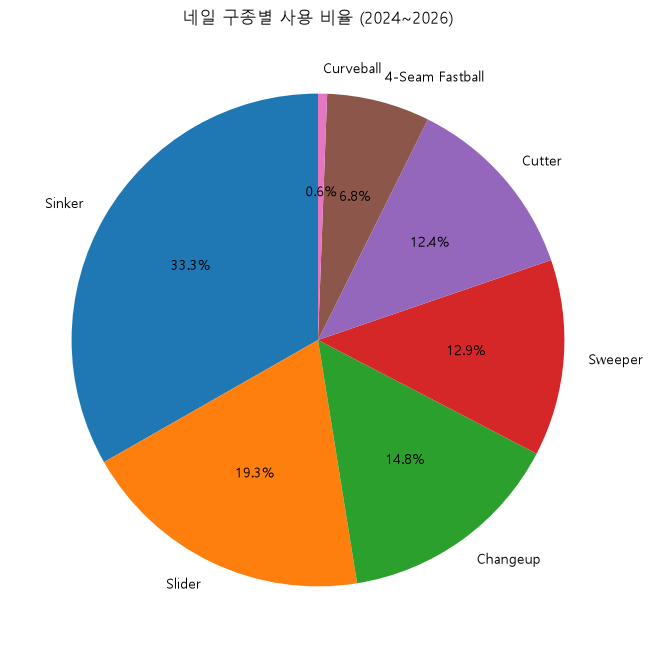

In [80]:
# 구종별 투구수
pitch_count = df_nail["pitch_name"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    pitch_count,
    labels=pitch_count.index,
    autopct="%.1f%%",   # 소수점 1자리까지 비율 표시
    startangle=90
)

plt.title("네일 구종별 사용 비율 (2024~2026)")
plt.show()

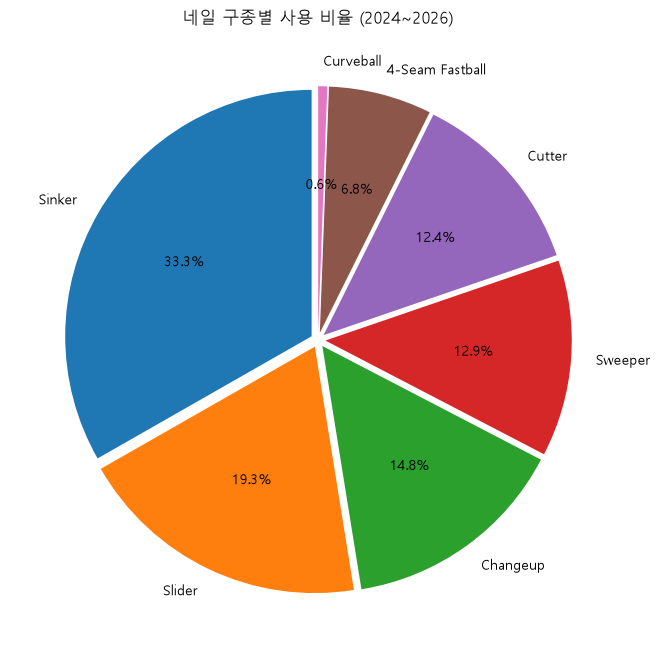

In [81]:
pitch_count = df_nail["pitch_name"].value_counts()

# 모든 조각을 0.03씩 바깥으로 띄우기
explode = [0.03] * len(pitch_count)

plt.figure(figsize=(8, 8))

plt.pie(
    pitch_count,
    labels=pitch_count.index,
    autopct="%.1f%%",
    startangle=90,
    explode=explode
)

plt.title("네일 구종별 사용 비율 (2024~2026)")
plt.show()